In [ ]:
from google.colab import files

uploaded = files.upload()

Saving credit_card_data.csv to credit_card_data.csv


In [ ]:
# Importer les bibliothèques, les classes, les fonctions et les modules

In [ ]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score
)

from torch.utils.data import TensorDataset, DataLoader, Subset, random_split
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Appareil utilisé : {device}")
# RANDOM_STATE = 42

# np.random.seed(RANDOM_STATE)
# torch.manual_seed(RANDOM_STATE)


Appareil utilisé : cpu


In [ ]:
# Lire le fichier existant
# read_csv() lit le CSV et retourne un DataFrame.

In [ ]:
credit_card = pd.read_csv('credit_card_data.csv') #credit_card = pd.read_csv('/content/credit_card_data.csv')

In [ ]:
credit_card

,distance_from_home,distance_from_last_transaction,ratio_to_median_purchase_price,repeat_retailer,used_chip,used_pin_number,online_order,fraud
0,57.877857,0.311140,1.945940,1.0,1.0,0.0,0.0,0.0
1,10.829943,0.175592,1.294219,1.0,0.0,0.0,0.0,0.0
2,5.091079,0.805153,0.427715,1.0,0.0,0.0,1.0,0.0
3,2.247564,5.600044,0.362663,1.0,1.0,0.0,1.0,0.0
4,44.190936,0.566486,2.222767,1.0,1.0,0.0,1.0,0.0
...,...,...,...,...,...,...,...,...
999995,2.207101,0.112651,1.626798,1.0,1.0,0.0,0.0,0.0
999996,19.872726,2.683904,2.778303,1.0,1.0,0.0,0.0,0.0
999997,2.914857,1.472687,0.218075,1.0,1.0,0.0,1.0,0.0
999998,4.258729,0.242023,0.475822,1.0,0.0,0.0,1.0,0.0


#***EDA***

In [ ]:
# 10000000 transcations + 8 colonnes(X= features + target)

In [ ]:
credit_card.shape

(1000000, 8)

In [ ]:
credit_card.head()

,distance_from_home,distance_from_last_transaction,ratio_to_median_purchase_price,repeat_retailer,used_chip,used_pin_number,online_order,fraud
0,57.877857,0.311140,1.945940,1.0,1.0,0.0,0.0,0.0
1,10.829943,0.175592,1.294219,1.0,0.0,0.0,0.0,0.0
2,5.091079,0.805153,0.427715,1.0,0.0,0.0,1.0,0.0
3,2.247564,5.600044,0.362663,1.0,1.0,0.0,1.0,0.0
4,44.190936,0.566486,2.222767,1.0,1.0,0.0,1.0,0.0


In [ ]:
#FEATURES: 7 , TARGET: fraud

In [ ]:
credit_card.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000000 entries, 0 to 999999
Data columns (total 8 columns):
 #   Column                          Non-Null Count    Dtype  
---  ------                          --------------    -----  
 0   distance_from_home              1000000 non-null  float64
 1   distance_from_last_transaction  1000000 non-null  float64
 2   ratio_to_median_purchase_price  1000000 non-null  float64
 3   repeat_retailer                 1000000 non-null  float64
 4   used_chip                       1000000 non-null  float64
 5   used_pin_number                 1000000 non-null  float64
 6   online_order                    1000000 non-null  float64
 7   fraud                           1000000 non-null  float64
dtypes: float64(8)
memory usage: 61.0 MB


In [ ]:
# On peut voir que les colonnes sont de type numérique(float64) ce qui facilite le prétraitement de données

In [ ]:
credit_card['fraud'].value_counts(normalize=True)

,proportion
fraud,
0.0,0.912597
1.0,0.087403


In [ ]:
credit_card['fraud'].value_counts()


,count
fraud,
0.0,912597
1.0,87403


Les données sont fortement déséquilibrées, puisqu’il y a beaucoup plus de transactions **non frauduleuses** que de transactions **frauduleuses.** Le jeu de données contient 1 000 000 de transactions, dont environ ****8,7 % sont frauduleuses.****


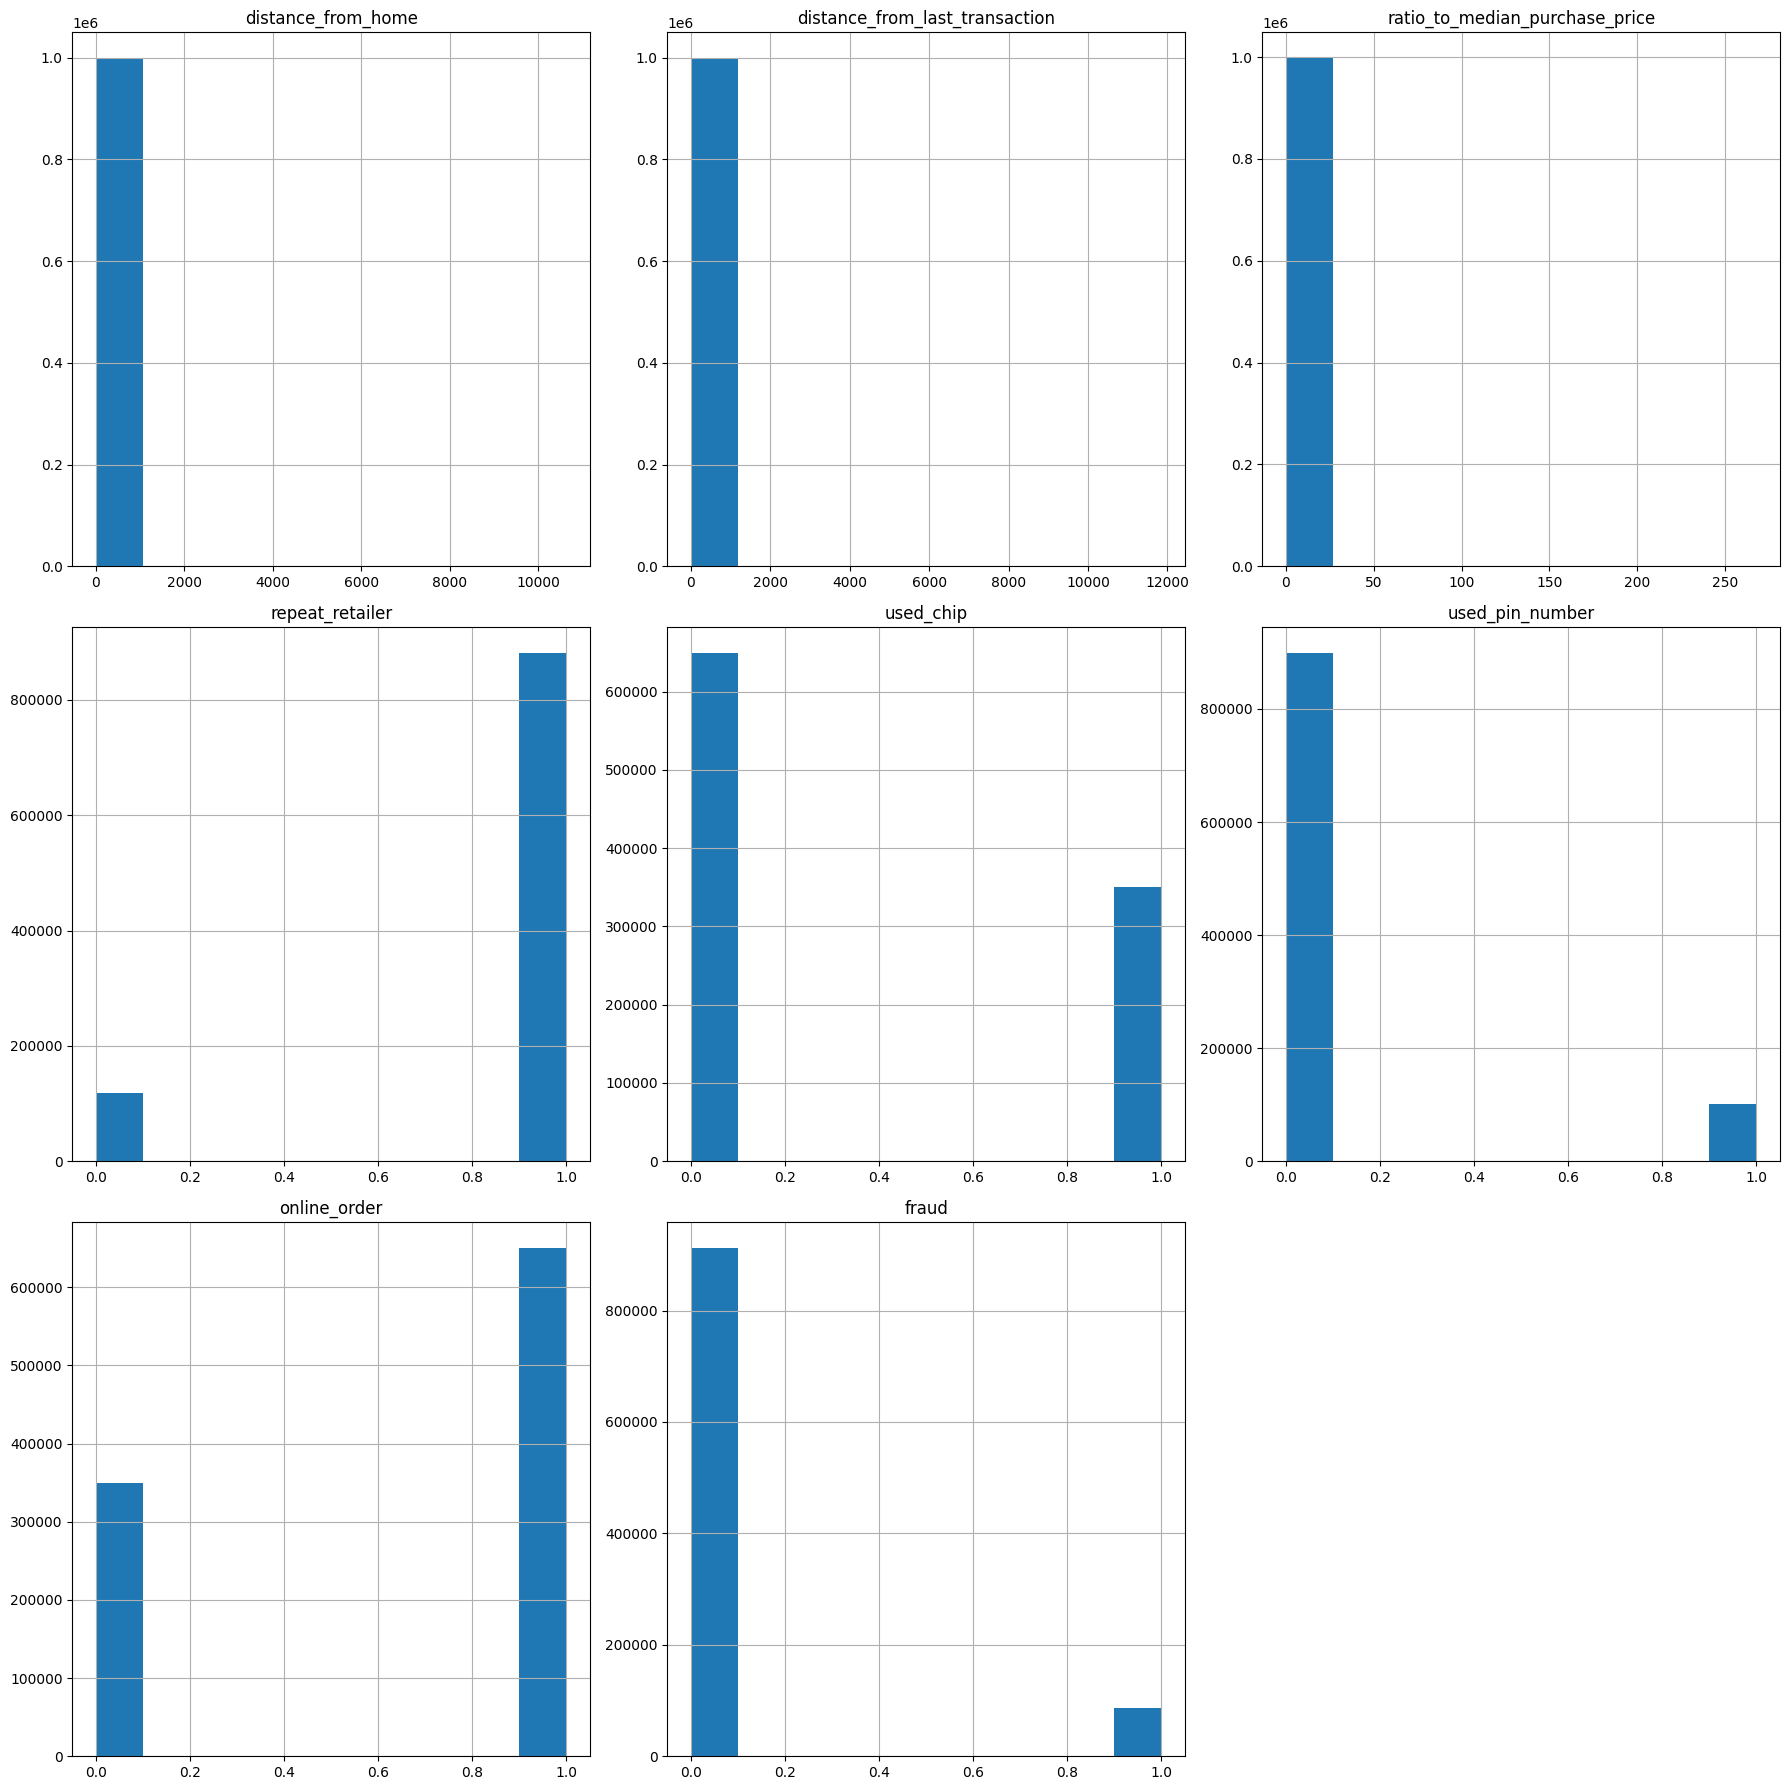

In [ ]:
credit_card.hist(figsize=(18, 18))
plt.tight_layout()
plt.show()

In [ ]:
# Nous observons des variables avec des échelles et
# des distributions différentes.
# Nous utilisons donc StandardScaler pour standardiser les données
# avant l'entraînement de l'autoencodeur.

In [ ]:
credit_card.isna().sum()

,0
distance_from_home,0
distance_from_last_transaction,0
ratio_to_median_purchase_price,0
repeat_retailer,0
used_chip,0
used_pin_number,0
online_order,0
fraud,0


Aucune variable contient des valeurs manquantes

In [ ]:
credit_card.nunique()

,0
distance_from_home,1000000
distance_from_last_transaction,1000000
ratio_to_median_purchase_price,1000000
repeat_retailer,2
used_chip,2
used_pin_number,2
online_order,2
fraud,2


In [ ]:
# Les 3 premières variables sont des variables quantitatives continues

In [ ]:
# Les autres variables sont des variables binaires et ne serviront pas
# analyser la distribution, l'échelle et les valeurs extrêmes,
# sans oublier que fraud est notre target(y).

In [ ]:
credit_card[['distance_from_home',
             'distance_from_last_transaction',
             'ratio_to_median_purchase_price']].describe()

,distance_from_home,distance_from_last_transaction,ratio_to_median_purchase_price
count,1000000.000000,1000000.000000,1000000.000000
mean,26.628792,5.036519,1.824182
std,65.390784,25.843093,2.799589
min,0.004874,0.000118,0.004399
25%,3.878008,0.296671,0.475673
50%,9.967760,0.998650,0.997717
75%,25.743985,3.355748,2.096370
max,10632.723672,11851.104565,267.802942


In [ ]:
# On remarque que les trois variables présentent une forte dispersion
# et des valeurs maximales très élevées par rapport aux quartiles.
# Par exemple, pour `distance_from_home`,
# 75 % des valeurs sont inférieures à 25,74 alors que
# le maximum atteint 10 632,72.
# De plus, la moyenne est supérieure à la médiane pour les trois variables, ce qui indique une asymétrie vers la droite.
# Ces observations suggèrent la présence de valeurs extrêmes
# et montrent que les variables sont sur des échelles très différentes.


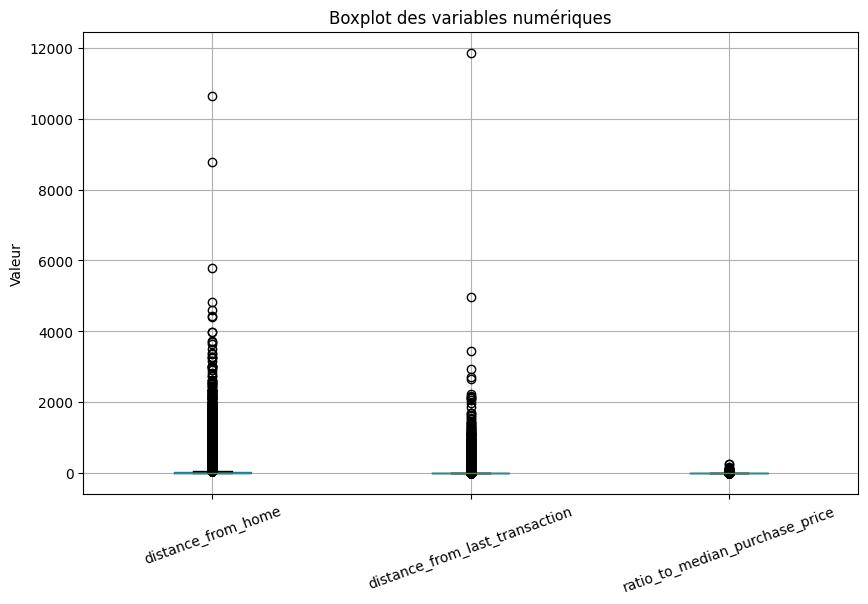

In [ ]:
import matplotlib.pyplot as plt

credit_card[['distance_from_home',
             'distance_from_last_transaction',
             'ratio_to_median_purchase_price']].boxplot(
    figsize=(10, 6)
)

plt.xticks(rotation=20)
plt.ylabel('Valeur')
plt.title('Boxplot des variables numériques')
plt.show()

In [ ]:
print("Doublons :", credit_card.duplicated().sum())


Doublons : 0


##*Le prétraitement des données*

In [ ]:
# Séparation des caractéristiques et du target

In [ ]:
X = credit_card.drop("fraud", axis=1)
y = credit_card["fraud"]

 **Détails sur les anomalies:  Le modèle apprendra à bien reconstruire les exemples normaux (faible
 erreur).**

In [ ]:
# Séparation des données d'entraînement, de validation et du test

In [ ]:
# 70 / 15 / 15 est plus équilibré parce que tu accordes davantage de données à la validation et au test.

In [ ]:
# réduire inutilement l'ensemble d'apprentissage n'apporte pas vraiment de bénéfice.

In [ ]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    stratify=y,
    random_state=22
)
# 70% TRAIN ET 30% TEMP(INUTILISÉES)

In [ ]:
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=42
)
# 15% VALIDATION ET 15% TEST

In [ ]:
print("Train :", X_train.shape)
print("Validation :", X_val.shape)
print("Test :", X_test.shape)

Train : (700000, 7)
Validation : (150000, 7)
Test : (150000, 7)


In [ ]:
X_train_normal = X_train[y_train == 0]
#les exemples normaux (faible erreur). --- fraud == 0
print("Transactions normales pour l'entraînement :", X_train_normal.shape)

Transactions normales pour l'entraînement : (638818, 7)


In [ ]:
X_val_normal = X_val[y_val == 0]

In [ ]:
# Pour déterminer le seuil, on devrait utiliser des transactions normales de validation.

In [ ]:
X_train_normal

,distance_from_home,distance_from_last_transaction,ratio_to_median_purchase_price,repeat_retailer,used_chip,used_pin_number,online_order
910455,20.294250,0.141362,4.176442,1.0,1.0,0.0,0.0
224178,13.819779,0.359904,1.149657,1.0,0.0,0.0,1.0
487474,45.622535,4.908488,4.633436,1.0,0.0,0.0,0.0
308595,5.313334,8.128392,2.650780,1.0,0.0,0.0,1.0
747378,0.288513,0.477656,0.517775,0.0,1.0,0.0,0.0
...,...,...,...,...,...,...,...
949412,5.259605,0.860121,4.637276,1.0,0.0,0.0,0.0
551457,1.597725,4.339547,0.169379,0.0,1.0,0.0,1.0
919744,34.254195,2.841264,0.720342,1.0,0.0,0.0,1.0
103913,34.405548,2.658928,0.161396,1.0,0.0,0.0,1.0


In [ ]:
# La standardisation a fonctionné comme prévu.

In [ ]:
scaler = StandardScaler()

X_train_normal = scaler.fit_transform(X_train_normal)
X_val = scaler.transform(X_val)
X_val_normal = scaler.transform(X_val_normal)
X_test = scaler.transform(X_test)

In [ ]:
print("Moyenne :", X_train_normal.mean(axis=0))
print("Écart-type :", X_train_normal.std(axis=0))

Moyenne : [ 3.41469119e-17 -6.21985445e-17  6.18648613e-17  6.47567822e-17
 -2.94531019e-17 -5.69485958e-18  9.55112485e-17]
Écart-type : [1. 1. 1. 1. 1. 1. 1.]


In [ ]:
# Pourquoi float32 ?

# Parce que c'est le format numérique standard utilisé par PyTorch
# pour l'entraînement des réseaux de neurones.

In [ ]:
X_train_normal = torch.tensor(
    X_train_normal,
    dtype=torch.float32
)

X_val_normal = torch.tensor(
    X_val_normal,
    dtype=torch.float32
)

X_val = torch.tensor(
    X_val,
    dtype=torch.float32
)

X_test = torch.tensor(
    X_test,
    dtype=torch.float32
)

In [ ]:
# Créer les DataLoaders

In [ ]:
train_dataset = TensorDataset(X_train_normal)
val_dataset = TensorDataset(X_val)
val_normal_dataset = TensorDataset(X_val_normal)
test_dataset = TensorDataset(X_test)

In [ ]:
# Le batch_size est défini comme hyperparamètre afin de tester plusieurs valeurs
# plutôt que d'utiliser une valeur fixe choisie arbitrairement.

In [ ]:
batch_size = 512
train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False
)

val_normal_loader = DataLoader(
    val_normal_dataset,
    batch_size=batch_size,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False
)


# Parce que l'autoencodeur apprend uniquement avec les transactions normales.

In [ ]:
# Auto-encodeur

In [ ]:
class ClassicAutoEncodeur(nn.Module):
    def __init__(self,inputs=7,d_latent=16):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(inputs,128), nn.ReLU(),
            nn.Linear(128, 64), nn.ReLU(),
            nn.Linear(64, d_latent),
        )
        self.decoder = nn.Sequential(
            nn.Linear(d_latent, 64), nn.ReLU(),
            nn.Linear(64, 128), nn.ReLU(),
            nn.Linear(128, inputs)#*
        )

    def forward(self, x):
        return self.decoder(self.encoder(x))

        #*Nos données sont tabulaires et ont été standardisées avec StandardScaler.
        # Elles peuvent donc prendre des valeurs négatives ou positives sans être limitées à [0,1].
        # Une Sigmoid limiterait la sortie du décodeur entre 0 et 1
        # et empêcherait de reconstruire correctement certaines valeurs.
        # Aucune activation finale n'est nécessaire
        # pour des données tabulaires standardisées.

In [ ]:
model = ClassicAutoEncodeur(7,16)
lot = X_train_normal[:128]

print(f"Code   : {tuple(model.encoder(lot).shape)}")
print(f"Sortie : {tuple(model(lot).shape)}")

def compter(module):
    return sum(p.numel() for p in module.parameters())

print(f"Paramètres de l'encodeur : {compter(model.encoder)}")
print(f"Paramètres du décodeur   : {compter(model.decoder)}")

Code   : (128, 16)
Sortie : (128, 7)
Paramètres de l'encodeur : 10320
Paramètres du décodeur   : 10311


In [ ]:
# La cible de la perte est l’entrée elle-même,
# avec criterion = nn.MSELoss()

def entrainer_modele(model, optimizer, epochs, patience, nom_fichier,
                     train_loader, val_loader, utiliser_early_stopping=True):

    # Fonction de perte : erreur quadratique moyenne
    loss_function = nn.MSELoss()

    train_losses = []
    val_losses = []

    meilleure_val_loss = float("inf")
    compteur = 0
    meilleure_epoque = 0

    model = model.to(device)

    for epoch in range(epochs):

        # -------------------------
        # ENTRAÎNEMENT
        # -------------------------

        model.train()

        total_train_loss = 0

        for (X_batch,) in train_loader:

            X_batch = X_batch.to(device)

            # Remettre les gradients à zéro
            optimizer.zero_grad()

            # Le modèle essaie de reconstruire X_batch
            reconstruction = model(X_batch)

            # On compare la reconstruction avec l'entrée originale
            loss = loss_function(reconstruction, X_batch)

            # Calcul des gradients
            loss.backward()

            # Mise à jour des poids
            optimizer.step()

            total_train_loss += loss.item()

        train_loss = total_train_loss / len(train_loader)

        train_losses.append(train_loss)

        # -------------------------
        # VALIDATION
        # -------------------------

        model.eval()

        total_val_loss = 0

        with torch.no_grad():

            for (X_batch,) in val_loader:

                X_batch = X_batch.to(device)

                # Reconstruction
                reconstruction = model(X_batch)

                # Comparaison avec l'entrée originale
                loss = loss_function(reconstruction, X_batch)

                total_val_loss += loss.item()

        val_loss = total_val_loss / len(val_loader)

        val_losses.append(val_loss)

        print(
            f"Époque {epoch + 1}: "
            f"perte entraînement={train_loss:.4f}, "
            f"perte validation={val_loss:.4f}"
        )

        # -------------------------
        # EARLY STOPPING
        # -------------------------

        if val_loss < meilleure_val_loss:

            meilleure_val_loss = val_loss
            meilleure_epoque = epoch + 1
            compteur = 0

            # Sauvegarder le meilleur modèle
            torch.save(
                model.state_dict(),
                nom_fichier
            )

        else:

            compteur += 1

        if utiliser_early_stopping and compteur >= patience:

            print(f"Arrêt à l'époque {epoch + 1}.")
            break

    # Recharger le meilleur modèle
    model.load_state_dict(
        torch.load(
            nom_fichier,
            weights_only=True
        )
    )

    return train_losses, val_losses, meilleure_epoque

In [ ]:
model_auto = ClassicAutoEncodeur(7, 16)

optimizer = torch.optim.Adam(
    model_auto.parameters(),
    lr=0.001
)

train_losses, val_losses, meilleure_epoque = entrainer_modele(
    model_auto,
    optimizer,
    40,
    10,
    "meilleur_modele.pt",
    train_loader,
    val_loader,
    True
)

Époque 1: perte entraînement=0.0396, perte validation=0.0012
Époque 2: perte entraînement=0.0023, perte validation=0.0010
Époque 3: perte entraînement=0.0015, perte validation=0.0007
Époque 4: perte entraînement=0.0013, perte validation=0.0005
Époque 5: perte entraînement=0.0017, perte validation=0.0009
Époque 6: perte entraînement=0.0016, perte validation=0.0008
Époque 7: perte entraînement=0.0047, perte validation=0.0007
Époque 8: perte entraînement=0.0011, perte validation=0.0006
Époque 9: perte entraînement=0.0008, perte validation=0.0031
Époque 10: perte entraînement=0.0016, perte validation=0.0004
Époque 11: perte entraînement=0.0061, perte validation=0.0009
Époque 12: perte entraînement=0.0020, perte validation=0.0009
Époque 13: perte entraînement=0.0014, perte validation=0.0008
Époque 14: perte entraînement=0.0051, perte validation=0.0007
Époque 15: perte entraînement=0.0021, perte validation=0.0014
Époque 16: perte entraînement=0.0030, perte validation=0.0228
Époque 17: perte 

In [ ]:
print(train_loader.dataset)
print(val_loader.dataset)


In [ ]:
for batch in train_loader:
    x = batch[0].to(device)
    print("Taille du batch :", x.shape)
    break

print(x)

Taille du batch : torch.Size([512, 7])
tensor([[-0.1795, -0.1707, -0.5896,  ...,  1.3325, -0.3517, -1.2831],
        [-0.4045, -0.1065,  0.2013,  ..., -0.7504, -0.3517, -1.2831],
        [ 0.2473, -0.1832, -0.1577,  ...,  1.3325, -0.3517, -1.2831],
        ...,
        [-0.3641,  0.6446, -0.3255,  ..., -0.7504,  2.8431, -1.2831],
        [-0.0789,  0.0198,  0.4119,  ...,  1.3325, -0.3517,  0.7794],
        [12.1976, -0.1614, -0.5422,  ..., -0.7504, -0.3517, -1.2831]])


In [ ]:
print("Batch size :", train_loader.batch_size)
print("Nombre de données :", len(train_loader.dataset))
print("Nombre de batches :", len(train_loader))

Batch size : 512
Nombre de données : 638818
Nombre de batches : 1248


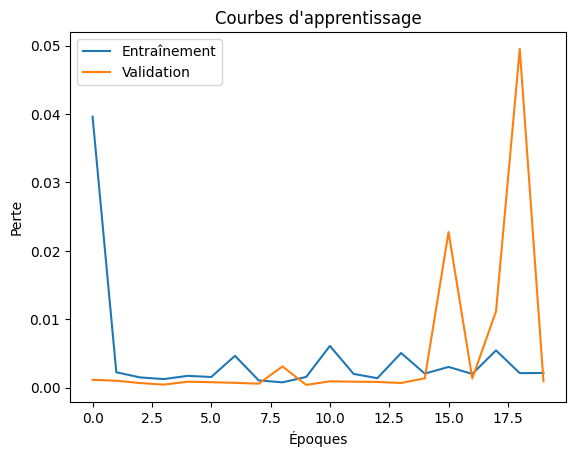

In [ ]:
plt.plot(train_losses, label="Entraînement")
plt.plot(val_losses, label="Validation")
plt.xlabel("Époques")
plt.ylabel("Perte")
plt.title("Courbes d'apprentissage")
plt.legend()
plt.show()


In [ ]:
resultats_batch = {}

for batch_size in [32, 64, 128, 256, 512]:

    print("\n==============================")
    print("Batch size :", batch_size)
    print("==============================")

    train_loader_temp = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True
    )

    val_loader_temp = DataLoader(
        val_dataset,
        batch_size=batch_size,
        shuffle=False
    )

    model_temp = ClassicAutoEncodeur(7, 16)

    optimizer_temp = torch.optim.Adam(
        model_temp.parameters(),
        lr=0.001
    )

    train_loss_temp, val_loss_temp, meilleure_epoque_temp = entrainer_modele(
        model_temp,
        optimizer_temp,
        20,
        5,
        f"modele_batch_{batch_size}.pt",
        train_loader_temp,
        val_loader_temp,
        True
    )

    resultats_batch[batch_size] = min(val_loss_temp)

print("\nRésultats :")

for batch_size, loss in resultats_batch.items():
    print(f"Batch size {batch_size} : meilleure MSE = {loss:.6f}")


Batch size : 32
Époque 1: perte entraînement=0.0230, perte validation=0.0026
Époque 2: perte entraînement=0.0074, perte validation=0.0038
Époque 3: perte entraînement=0.0095, perte validation=0.0077
Époque 4: perte entraînement=0.0112, perte validation=0.0637
Époque 5: perte entraînement=0.0279, perte validation=0.0075
Époque 6: perte entraînement=0.0188, perte validation=0.0114
Arrêt à l'époque 6.

Batch size : 64
Époque 1: perte entraînement=0.0097, perte validation=0.0021
Époque 2: perte entraînement=0.0061, perte validation=0.0024
Époque 3: perte entraînement=0.0051, perte validation=0.0017
Époque 4: perte entraînement=0.0074, perte validation=0.0076
Époque 5: perte entraînement=0.0056, perte validation=0.0106
Époque 6: perte entraînement=0.0173, perte validation=0.0059
Époque 7: perte entraînement=0.0073, perte validation=0.0168
Époque 8: perte entraînement=0.0285, perte validation=0.0508
Arrêt à l'époque 8.

Batch size : 128
Époque 1: perte entraînement=0.0123, perte validation=

In [ ]:
meilleur_batch = min(
    resultats_batch,
    key=resultats_batch.get
)

print("Meilleur batch size :", meilleur_batch)

# Pourquoi min() ?

# Parce que notre métrique ici est la MSE.

# Donc :

# petite MSE = meilleure reconstruction

Meilleur batch size : 512


In [ ]:
# Deuxième autoencodeur : débruitant

In [ ]:
class DenoisingAutoEncodeur(nn.Module):

    def __init__(self, inputs=7, d_latent=16):

        super().__init__()

        self.encoder = nn.Sequential(
            nn.Linear(inputs, 128),
            nn.ReLU(),

            nn.Linear(128, 64),
            nn.ReLU(),

            nn.Linear(64, d_latent)
        )

        self.decoder = nn.Sequential(
            nn.Linear(d_latent, 64),
            nn.ReLU(),

            nn.Linear(64, 128),
            nn.ReLU(),

            nn.Linear(128, inputs)
        )

    def forward(self, x):

        code = self.encoder(x)

        reconstruction = self.decoder(code)

        return reconstruction

In [ ]:
def ajouter_bruit(x, bruit=0.1):

    bruit_aleatoire = torch.randn_like(x) * bruit

    return x + bruit_aleatoire

In [ ]:
x = X_train_normal[:5].to(device)

x_bruite = ajouter_bruit(x)

print("Original :")
print(x)

print("\nAvec bruit :")
print(x_bruite)

Original :
tensor([[-0.0476, -0.1786,  1.4256,  0.3667,  1.3325, -0.3517, -1.2831],
        [-0.1690, -0.1692, -0.1422,  0.3667, -0.7504, -0.3517,  0.7794],
        [ 0.4270,  0.0262,  1.6623,  0.3667, -0.7504, -0.3517, -1.2831],
        [-0.3283,  0.1645,  0.6353,  0.3667, -0.7504, -0.3517,  0.7794],
        [-0.4225, -0.1641, -0.4695, -2.7267,  1.3325, -0.3517, -1.2831]])

Avec bruit :
tensor([[-0.2046, -0.1994,  1.5152,  0.6063,  1.3974, -0.3716, -1.2046],
        [-0.1920, -0.2638,  0.0553,  0.4773, -0.7144, -0.4048,  0.8158],
        [ 0.3489,  0.0920,  1.6502,  0.3349, -0.6023, -0.3058, -1.3980],
        [-0.2819,  0.0483,  0.5991,  0.5347, -0.7086, -0.4346,  0.7876],
        [-0.4205, -0.3266, -0.3981, -2.8501,  1.3077, -0.2797, -1.3710]])


In [ ]:
def entrainer_denoising(model, optimizer, epochs, patience,
                        nom_fichier, train_loader, val_loader):

    loss_function = nn.MSELoss()

    train_losses = []
    val_losses = []

    meilleure_val_loss = float("inf")
    compteur = 0

    model = model.to(device)

    for epoch in range(epochs):

        model.train()

        total_train_loss = 0

        for (X_batch,) in train_loader:

            X_batch = X_batch.to(device)

            # Ajouter du bruit à l'entrée
            x_bruite = ajouter_bruit(X_batch, 0.1)

            optimizer.zero_grad()

            reconstruction = model(x_bruite)

            # On compare avec l'original
            loss = loss_function(reconstruction, X_batch)

            loss.backward()

            optimizer.step()

            total_train_loss += loss.item()

        train_loss = total_train_loss / len(train_loader)
        train_losses.append(train_loss)

        # Validation
        model.eval()

        total_val_loss = 0

        with torch.no_grad():

            for (X_batch,) in val_loader:

                X_batch = X_batch.to(device)

                x_bruite = ajouter_bruit(X_batch, 0.1)

                reconstruction = model(x_bruite)

                loss = loss_function(reconstruction, X_batch)

                total_val_loss += loss.item()

        val_loss = total_val_loss / len(val_loader)

        val_losses.append(val_loss)

        print(
            f"Époque {epoch + 1}: "
            f"train={train_loss:.4f}, "
            f"val={val_loss:.4f}"
        )

        if val_loss < meilleure_val_loss:

            meilleure_val_loss = val_loss
            compteur = 0

            torch.save(model.state_dict(), nom_fichier)

        else:

            compteur += 1

        if compteur >= patience:

            print("Early stopping.")
            break

    model.load_state_dict(
        torch.load(nom_fichier, weights_only=True)
    )

    return train_losses, val_losses

In [ ]:
denoising_model = DenoisingAutoEncodeur(
    inputs=7,
    d_latent=16
)

optimizer_denoising = torch.optim.Adam(
    denoising_model.parameters(),
    lr=0.001
)

train_denoising, val_denoising = entrainer_denoising(
    denoising_model,
    optimizer_denoising,
    20,
    5,
    "denoising_autoencodeur.pt",
    train_loader,
    val_loader
)

Époque 1: train=0.0416, val=0.0057
Époque 2: train=0.0057, val=0.0048
Époque 3: train=0.0060, val=0.0041
Époque 4: train=0.0052, val=0.0039
Époque 5: train=0.0049, val=0.0062
Époque 6: train=0.0058, val=0.0041
Époque 7: train=0.0081, val=0.0042
Époque 8: train=0.0064, val=0.0040
Époque 9: train=0.0040, val=0.0044
Early stopping.


Autoencodeur classique :
Meilleure validation : 0.00041177241059549394

Autoencodeur débruitant :
Meilleure validation : 0.00387664889891349
Modèle choisi : Classique
Meilleure MSE : 0.00041177241059549394


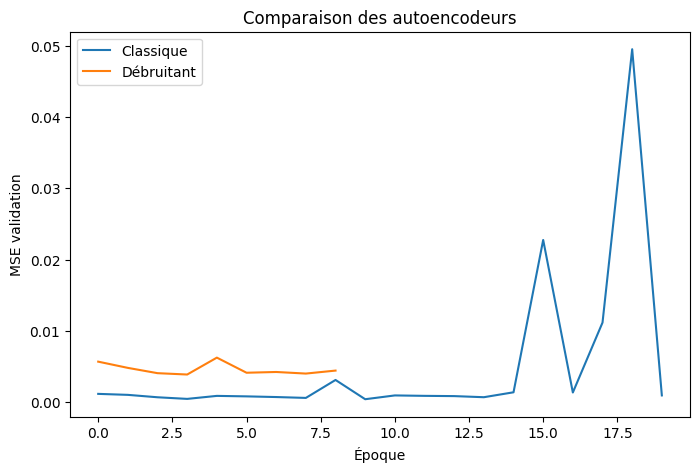

In [ ]:
print("Autoencodeur classique :")
print("Meilleure validation :", min(val_losses))

print("\nAutoencodeur débruitant :")
print("Meilleure validation :", min(val_denoising))

meilleure_loss_classique = min(val_losses)
meilleure_loss_denoising = min(val_denoising)

if meilleure_loss_denoising < meilleure_loss_classique:
    meilleur_modele = denoising_model
    nom_modele = "Débruitant"
    meilleure_loss = meilleure_loss_denoising
else:
    meilleur_modele = model_auto
    nom_modele = "Classique"
    meilleure_loss = meilleure_loss_classique

print("Modèle choisi :", nom_modele)
print("Meilleure MSE :", meilleure_loss)


plt.figure(figsize=(8, 5))

plt.plot(val_losses, label="Classique")
plt.plot(val_denoising, label="Débruitant")

plt.xlabel("Époque")
plt.ylabel("MSE validation")
plt.title("Comparaison des autoencodeurs")

plt.legend()
plt.show()

In [ ]:
def calculer_erreurs(model, data_loader):

    model.eval()

    erreurs = []

    with torch.no_grad():

        for (X_batch,) in data_loader:

            X_batch = X_batch.to(device)

            reconstruction = model(X_batch)

            # Erreur pour chaque transaction
            erreur = torch.mean(
                (X_batch - reconstruction) ** 2,
                dim=1
            )

            erreurs.extend(
                erreur.cpu().numpy()
            )

    return np.array(erreurs)

In [ ]:
erreurs_test = calculer_erreurs(
    meilleur_modele,
    test_loader
)

print("Nombre d'erreurs :", len(erreurs_test))
print("Premières erreurs :", erreurs_test[:10])

Nombre d'erreurs : 150000
Premières erreurs : [1.5836426e-05 9.6895719e-06 2.4097529e-04 9.9733861e-06 1.1115542e-04
 1.5329753e-05 7.7512173e-05 8.9586729e-06 1.1749508e-05 1.1851739e-04]


In [ ]:
erreurs_normales = calculer_erreurs(
    meilleur_modele,
    val_normal_loader
)

# Créer le vrai seuil

In [ ]:
seuil = np.percentile(
    erreurs_normales,
    95
)

print("Seuil de détection :", seuil)

Seuil de détection : 0.0002498626


In [ ]:
erreurs_test = calculer_erreurs(
    meilleur_modele,
    test_loader
)
predictions = (erreurs_test > seuil).astype(int)

In [ ]:
y_test_numpy = y_test.to_numpy()

In [ ]:
print("Precision :", precision_score(y_test_numpy, predictions))
print("Recall    :", recall_score(y_test_numpy, predictions))
print("F1-score  :", f1_score(y_test_numpy, predictions))

Precision : 0.6000704928625976
Recall    : 0.7791762013729977
F1-score  : 0.6779942255998407


In [ ]:
print("Precision :", precision_score(y_test_numpy, predictions))
print("Recall    :", recall_score(y_test_numpy, predictions))
print("F1-score  :", f1_score(y_test_numpy, predictions))

Precision : 0.6000704928625976
Recall    : 0.7791762013729977
F1-score  : 0.6779942255998407


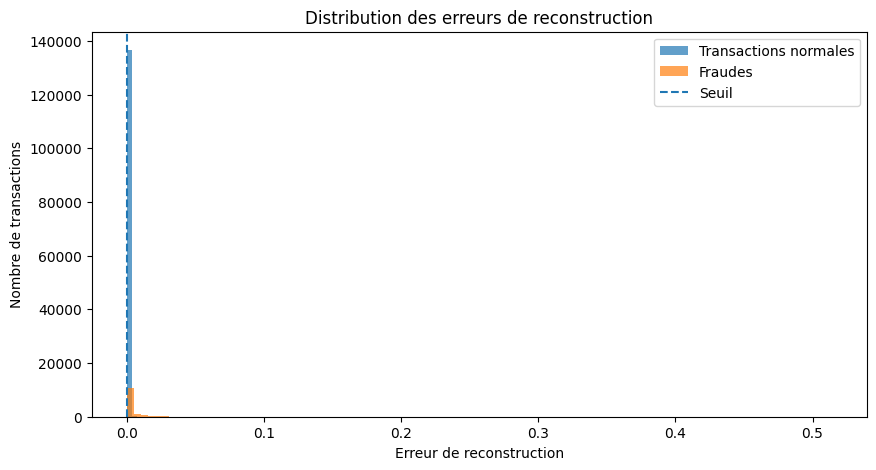

In [ ]:
plt.figure(figsize=(10, 5))

plt.hist(
    erreurs_test[y_test_numpy == 0],
    bins=100,
    alpha=0.7,
    label="Transactions normales"
)

plt.hist(
    erreurs_test[y_test_numpy == 1],
    bins=100,
    alpha=0.7,
    label="Fraudes"
)

plt.axvline(
    seuil,
    linestyle="--",
    label="Seuil"
)

plt.xlabel("Erreur de reconstruction")
plt.ylabel("Nombre de transactions")
plt.title("Distribution des erreurs de reconstruction")

plt.legend()
plt.show()

In [ ]:
indices_anomalies = np.argsort(erreurs_test)[-10:]

print("10 transactions avec les plus grandes erreurs :")

for indice in indices_anomalies[::-1]:

    print(
        f"Index : {indice} | "
        f"Erreur : {erreurs_test[indice]:.4f} | "
        f"Fraude réelle : {y_test_numpy[indice]}"
    )

10 transactions avec les plus grandes erreurs :
Index : 28305 | Erreur : 0.5140 | Fraude réelle : 1.0
Index : 96469 | Erreur : 0.3691 | Fraude réelle : 0.0
Index : 124648 | Erreur : 0.2824 | Fraude réelle : 1.0
Index : 144433 | Erreur : 0.2554 | Fraude réelle : 1.0
Index : 141459 | Erreur : 0.2414 | Fraude réelle : 1.0
Index : 128580 | Erreur : 0.2052 | Fraude réelle : 0.0
Index : 101568 | Erreur : 0.2039 | Fraude réelle : 0.0
Index : 22695 | Erreur : 0.1624 | Fraude réelle : 1.0
Index : 55351 | Erreur : 0.1385 | Fraude réelle : 1.0
Index : 12290 | Erreur : 0.1322 | Fraude réelle : 1.0


In [ ]:
torch.save(
    meilleur_modele.state_dict(),
    "autoencodeur_final.pt"
)

print("Modèle sauvegardé.")

Modèle sauvegardé.


In [ ]:
modele_recharge = ClassicAutoEncodeur(
    inputs=7,
    d_latent=16
)

modele_recharge.load_state_dict(
    torch.load(
        "autoencodeur_final.pt",
        weights_only=True
    )
)

modele_recharge = modele_recharge.to(device)

modele_recharge.eval()

print("Modèle rechargé avec succès.")

Modèle rechargé avec succès.


In [ ]:
# Calcul des erreurs sur les transactions de test
erreurs_test_recharge = calculer_erreurs(
    modele_recharge,
    test_loader
)

# Calcul des erreurs sur les transactions normales de validation
erreurs_normales_recharge = calculer_erreurs(
    modele_recharge,
    val_normal_loader
)

print("Nombre d'erreurs test :", len(erreurs_test_recharge))
print("Nombre d'erreurs normales validation :", len(erreurs_normales_recharge))

Nombre d'erreurs test : 150000
Nombre d'erreurs normales validation : 136889


In [ ]:
# Seuil basé sur le 95e percentile des transactions normales
seuil_recharge = np.percentile(
    erreurs_normales_recharge,
    95
)

print("Seuil :", seuil_recharge)

Seuil : 0.0002498626


In [ ]:
# 1 = anomalie, 0 = normale
predictions_recharge = (
    erreurs_test_recharge > seuil_recharge
).astype(int)

print("Nombre de transactions détectées comme anomalies :",
      predictions_recharge.sum())

Nombre de transactions détectées comme anomalies : 17023


In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score

precision = precision_score(y_test, predictions_recharge)
recall = recall_score(y_test, predictions_recharge)
f1 = f1_score(y_test, predictions_recharge)

print("Precision :", precision)
print("Recall :", recall)
print("F1-score :", f1)

Precision : 0.6000704928625976
Recall : 0.7791762013729977
F1-score : 0.6779942255998407


In [ ]:
print(f"Precision : {precision*100:.2f}%")
print(f"Recall    : {recall*100:.2f}%")
print(f"F1-score  : {f1*100:.2f}%")

Precision : 60.01%
Recall    : 77.92%
F1-score  : 67.80%


[[130082   6808]
 [  2895  10215]]


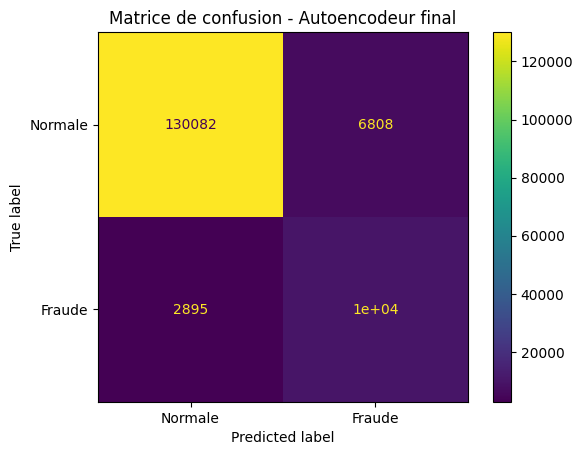

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, predictions_recharge)

print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Normale", "Fraude"]
)

disp.plot()
plt.title("Matrice de confusion - Autoencodeur final")
plt.show()

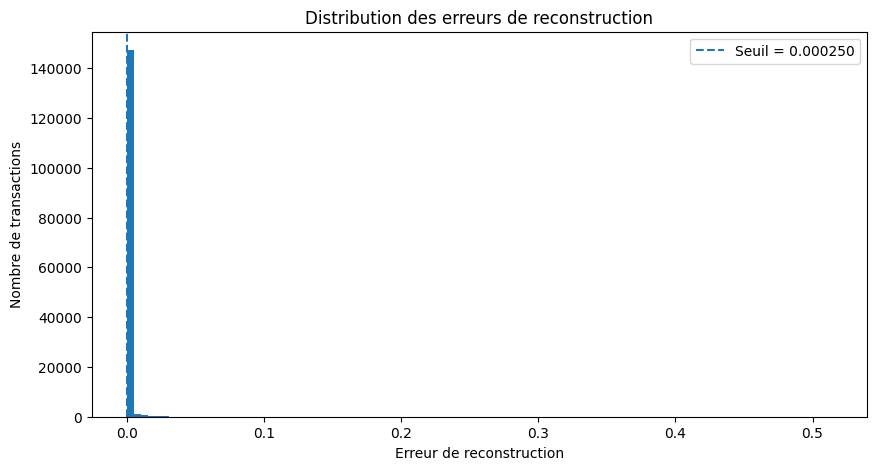

In [ ]:
plt.figure(figsize=(10, 5))

plt.hist(erreurs_test_recharge, bins=100)

plt.axvline(
    seuil_recharge,
    linestyle="--",
    label=f"Seuil = {seuil_recharge:.6f}"
)

plt.xlabel("Erreur de reconstruction")
plt.ylabel("Nombre de transactions")
plt.title("Distribution des erreurs de reconstruction")
plt.legend()
plt.show()

## Conclusion

L'autoencodeur a été entraîné uniquement sur les transactions normales afin
d'apprendre leur comportement.

L'erreur de reconstruction permet ensuite d'identifier les transactions
atypiques. Un seuil basé sur le 95e percentile des erreurs des transactions
normales de validation a été utilisé pour distinguer les anomalies.

Le modèle final a été sauvegardé dans `autoencodeur_final.pt`, puis rechargé
avec succès afin de vérifier que le modèle sauvegardé peut être réutilisé.

Les performances sont évaluées avec la précision, le rappel et le F1-score.
Une erreur de reconstruction élevée ne signifie pas nécessairement qu'une
transaction est frauduleuse : elle peut simplement être atypique.
